# A11 预测到客流后，应该安排多少工作人员？

把客流点预测转为排班人数，再比较风险缓冲与固定人数。使用独立模拟样本学习 split conformal 校准，分别报告预测误差、覆盖率和决策成本。

先修：B07、B15；先区分预测区间与平均误差，再学习成本函数。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 定义目标与四份独立数据
每行是一个独立活动时段，输入为小时、周末标志与活动强度；本例不把相邻时间当独立观测。训练拟合模型，校准构造区间，验证选择配置策略，测试结算成本。每人每小时可服务 20 人，工资 30，缺口每人次损失 8，均为假设。

In [2]:
import numpy as np,pandas as pd,json,math
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
rng=np.random.default_rng(111)
def generate_slots(n):
    x=pd.DataFrame({'hour':rng.integers(9,20,n),'weekend':rng.integers(0,2,n),'intensity':rng.uniform(0,1,n)})
    mean=35+45*np.exp(-((x['hour']-14)/3)**2)+20*x['weekend']+35*x['intensity']
    return x,rng.poisson(mean).astype(float)
X_train,y_train=generate_slots(500); X_cal,y_cal=generate_slots(200)
X_val,y_val=generate_slots(200); X_test,y_test=generate_slots(250)
capacity,wage,shortage_cost=20,30,8
model=HistGradientBoostingRegressor(max_iter=90,max_leaf_nodes=12,random_state=111).fit(X_train,y_train)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
linear_model=make_pipeline(StandardScaler(),Ridge(alpha=1)).fit(X_train,y_train)


## 2. 从点预测到校准区间
把独立校准集绝对残差排序，取 ceil((n+1)×0.9) 对应顺序统计量。代码把有限样本分位数写出来，避免神秘 API。独立可交换样本下是边际覆盖保证，不保证每个小时、每个子群或每批有限测试数据恰好 90%；实测覆盖不足仍须如实报告，不能看测试后改区间。

In [3]:
alpha=0.1
calibration_residuals=np.abs(y_cal-model.predict(X_cal))
rank=min(len(calibration_residuals),math.ceil((len(calibration_residuals)+1)*(1-alpha)))
q=float(np.sort(calibration_residuals)[rank-1])
def staffing_predictions(x):
    point=np.maximum(model.predict(x),0)
    return {'fixed':np.full(len(x),math.ceil(y_train.mean()/capacity),dtype=int),
            'linear_mean':np.ceil(np.maximum(linear_model.predict(x),0)/capacity).astype(int),
            'mean':np.ceil(point/capacity).astype(int),
            'buffered':np.ceil((point+q)/capacity).astype(int)}
def evaluate_staff(staff,actual):
    gap=np.maximum(actual-staff*capacity,0)
    return {'cost':float(np.mean(staff*wage+gap*shortage_cost)),'mean_staff':float(np.mean(staff)),'shortage_rate':float(np.mean(gap>0)),'mean_shortage':float(gap.mean())}


## 3. 用验证成本选择策略
覆盖率高不代表排班经济：多安排人有成本。对固定、线性预测、树模型预测、树模型加缓冲四种策略，在完全相同客流上比较成本。另列两种模型的 MAE 与同一人数转换规则下的成本，检查预测分数排序是否等于行动成本排序；排序可能一致，也可能不同。选择只使用验证集。

In [4]:
validation_scores={name:evaluate_staff(staff,y_val) for name,staff in staffing_predictions(X_val).items()}
selected=min(validation_scores,key=lambda name:validation_scores[name]['cost'])
test_staff=staffing_predictions(X_test)
test_scores={name:evaluate_staff(staff,y_test) for name,staff in test_staff.items()}
point=model.predict(X_test); lower=np.maximum(point-q,0); upper=point+q
coverage=float(np.mean((y_test>=lower)&(y_test<=upper)))
model_comparison=[]
for name,estimator,policy in [('ridge',linear_model,'linear_mean'),('hist_gradient_boosting',model,'mean')]:
    model_comparison.append({'model':name,'validation_mae':float(mean_absolute_error(y_val,estimator.predict(X_val))),
                            'test_mae':float(mean_absolute_error(y_test,estimator.predict(X_test))),
                            'validation_decision_cost':validation_scores[policy]['cost'],'test_decision_cost':test_scores[policy]['cost']})
pd.DataFrame(model_comparison).to_csv(OUT_DIR/'prediction_vs_decision.csv',index=False)


## 4. 给出有条件的人员建议
交付每个时段人数、缺口和政策比较，并把建议写成可复核文本。实际运营还需轮班连续性与技能约束；本例只解决时段人数，不假装已完成完整排班。

In [5]:
results=X_test.assign(actual=y_test,point=point,lower=lower,upper=upper)
for name,staff in test_staff.items(): results[name+'_staff']=staff
results.to_csv(OUT_DIR/'staffing.csv',index=False)
metrics={'selected_on_validation':selected,'validation':validation_scores,'test':test_scores,'model_comparison':model_comparison,'test_mae':float(mean_absolute_error(y_test,point)),'interval_coverage':coverage,'mean_interval_width':float(np.mean(upper-lower)),'nominal_coverage':0.9}
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
advice=f'验证集选择 {selected} 策略。独立测试平均成本 {test_scores[selected]["cost"]:.2f}，缺口时段比例 {test_scores[selected]["shortage_rate"]:.1%}；固定人数成本 {test_scores["fixed"]["cost"]:.2f}。经验区间覆盖 {coverage:.1%}。建议仅适用于每人容量 {capacity}、工资 {wage}、缺口代价 {shortage_cost} 的假设；容量、客流分布或工资改变后重新评估。'
if coverage < 0.9:
    advice += ' 本次有限测试集覆盖低于 90% 名义目标，须继续收集独立校准与验证数据并检查子群覆盖；不能把边际保证解读为当前每批数据必达标。'
(OUT_DIR/'决策建议.md').write_text('# 人员配置建议\n\n'+advice,encoding='utf-8')
pd.DataFrame(test_scores).T['cost'].plot.bar(); plt.ylabel('每时段平均总成本'); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(OUT_DIR/'staffing_cost.png'); plt.close(); print(metrics)


{'selected_on_validation': 'mean', 'validation': {'fixed': {'cost': 179.24, 'mean_staff': 5.0, 'shortage_rate': 0.205, 'mean_shortage': 3.655}, 'linear_mean': {'cost': 173.04, 'mean_staff': 4.74, 'shortage_rate': 0.275, 'mean_shortage': 3.855}, 'mean': {'cost': 152.36, 'mean_staff': 4.72, 'shortage_rate': 0.18, 'mean_shortage': 1.345}, 'buffered': {'cost': 165.43, 'mean_staff': 5.485, 'shortage_rate': 0.02, 'mean_shortage': 0.11}}, 'test': {'fixed': {'cost': 181.712, 'mean_staff': 5.0, 'shortage_rate': 0.276, 'mean_shortage': 3.964}, 'linear_mean': {'cost': 177.608, 'mean_staff': 4.684, 'shortage_rate': 0.34, 'mean_shortage': 4.636}, 'mean': {'cost': 152.128, 'mean_staff': 4.72, 'shortage_rate': 0.22, 'mean_shortage': 1.316}, 'buffered': {'cost': 164.392, 'mean_staff': 5.468, 'shortage_rate': 0.016, 'mean_shortage': 0.044}}, 'model_comparison': [{'model': 'ridge', 'validation_mae': 14.07781932436093, 'test_mae': 16.11330750501616, 'validation_decision_cost': 173.04, 'test_decision_cost

## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

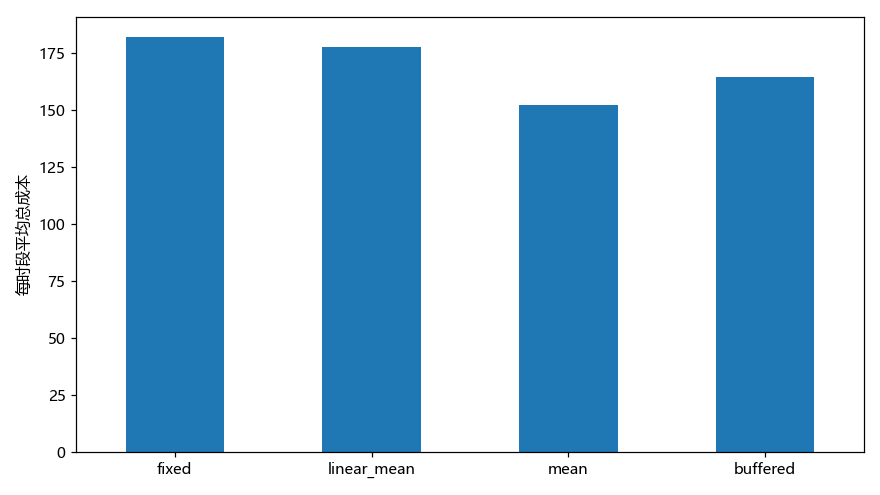

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
独立模拟时段满足教学假设，真实相邻时段可能相关；不能直接照搬交换性覆盖保证。区间不是排班目标，人数还需要结合成本与硬限制。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。